Dataset: 569 samples, 30 features
Classes: 0 = malignant, 1 = benign -> {np.int64(0): np.int64(212), np.int64(1): np.int64(357)}
Running Baseline with 30 features ...
Running PCA with 2 features ...
Running PCA with 5 features ...
Running PCA with 10 features ...
Running PCA with 15 features ...
Running PCA with 20 features ...
Running SelectKBest with 2 features ...
Running SelectKBest with 5 features ...
Running SelectKBest with 10 features ...
Running SelectKBest with 15 features ...
Running SelectKBest with 20 features ...

TABLE 1 - PERFORMANCE AND COST (mean +/- std over 50 CV runs)
     Method  Features     Accuracy %    Precision %       Recall %           F1 %  Acc change (pts)  Train-Test gap (pts)  Pipeline time (ms)  Classifier time (ms)
   Baseline        30 97.89 +/- 1.42 98.56 +/- 1.51 95.76 +/- 3.36 97.11 +/- 1.98              0.00                  0.97               37.25                22.865
        PCA         2 94.92 +/- 1.87 94.31 +/- 3.29 92.07 +/- 4.54 93.08 +/-

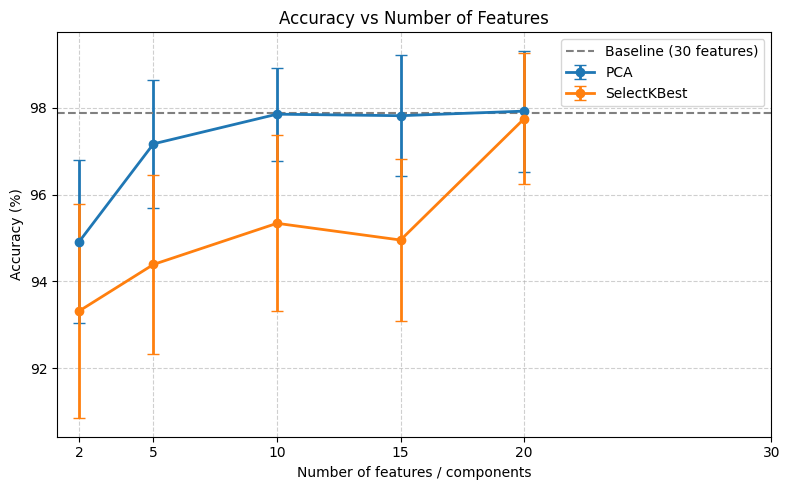

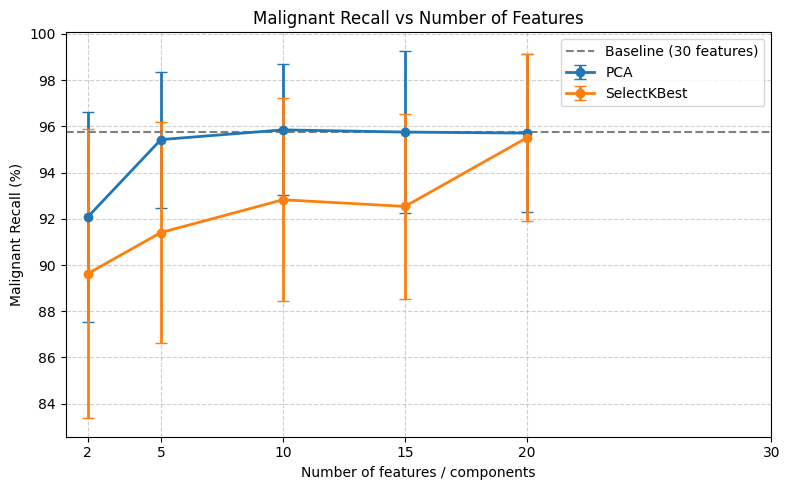

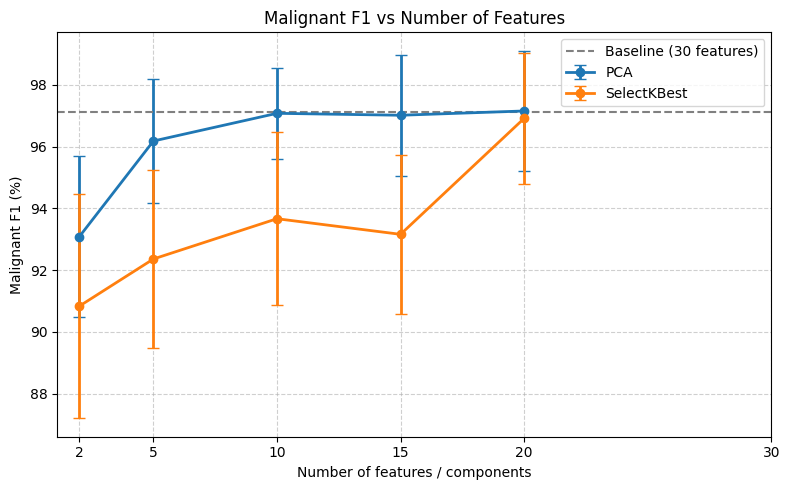

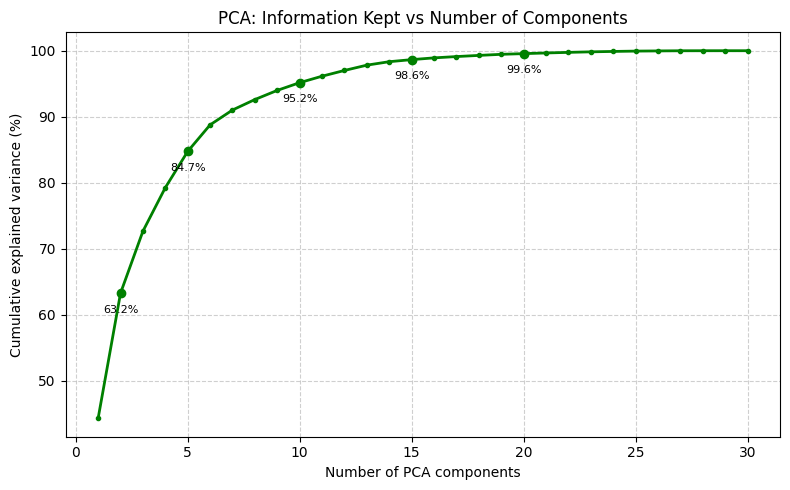

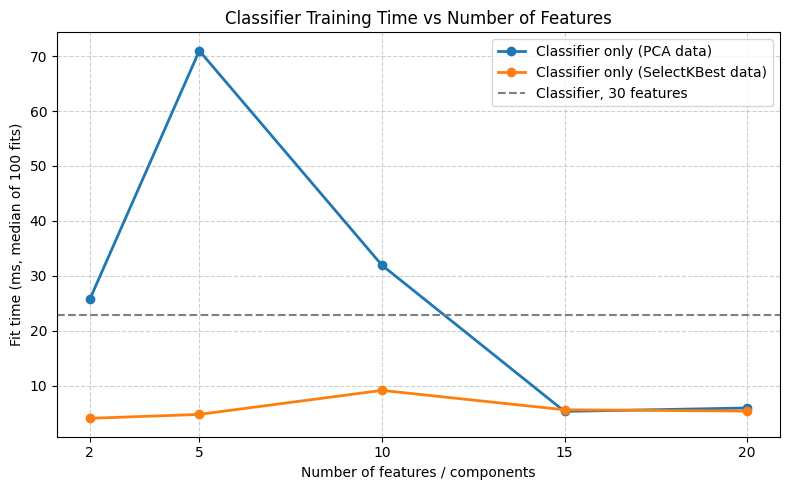


Done. Saved 2 tables (.csv) and 5 graphs (.png).


In [1]:
# ============================================================
# GROUP 13 - DIMENSIONALITY REDUCTION
# Research Question:
#   Does reducing dimensionality necessarily reduce
#   predictive performance?
#
# What this script does:
#   1. Loads the breast cancer dataset (30 features)
#   2. Reduces the features with two methods: PCA and SelectKBest
#   3. Evaluates each setting with repeated cross-validation
#   4. Compares everything with the 30-feature baseline
#   5. Saves 2 tables (.csv) and 5 graphs (.png)
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score


# ------------------------------------------------------------
# 1. SETTINGS (change experiment settings here)
# ------------------------------------------------------------
SEED = 42
DIMENSIONS = [2, 5, 10, 15, 20]       # Feature counts we want to test to see the performance trade-off
METHODS = ["PCA", "SelectKBest"]      # Unsupervised (PCA) vs Supervised (SelectKBest) feature reduction

# 5-fold CV repeated 10 times = 50 evaluations per setting.
# WHY WE DO THIS: Averaging over 50 runs ensures our results are stable
# and not biased by a single lucky or unlucky random train/test split.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)


# ------------------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------------------
dataset = load_breast_cancer()
X, y = dataset.data, dataset.target
N_FEATURES = X.shape[1]  # Total original features = 30

print(f"Dataset: {X.shape[0]} samples, {N_FEATURES} features")
print("Classes: 0 = malignant, 1 = benign ->", dict(zip(*np.unique(y, return_counts=True))))


# ------------------------------------------------------------
# 3. METRICS
# In breast cancer detection (0 = malignant, 1 = benign), missing
# a malignant tumor is dangerous. Therefore, precision, recall,
# and F1-score are tracked specifically for the MALIGNANT class (pos_label=0).
# ------------------------------------------------------------
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=0),
    "recall": make_scorer(recall_score, pos_label=0),
    "f1": make_scorer(f1_score, pos_label=0),
}
METRICS = list(scoring)


# ------------------------------------------------------------
# 4. BUILD A MODEL PIPELINE
# CRITICAL FOR NO DATA LEAKAGE: StandardScaler and feature reduction
# are placed inside the Pipeline. This ensures they are fitted ONLY
# on the training folds, preventing information from leaking into validation folds.
# ------------------------------------------------------------
def make_pipeline(method, k):
    steps = [("scaler", StandardScaler())] # Always scale features first for PCA/Logistic Regression

    if method == "PCA":
        # Unsupervised linear dimensionality reduction (projects data onto axes of max variance)
        steps.append(("reduction", PCA(n_components=k, random_state=SEED)))
    elif method == "SelectKBest":
        # Supervised feature selection (selects top k features based on statistical ANOVA F-value)
        steps.append(("reduction", SelectKBest(score_func=f_classif, k=k)))

    # Classification model used across all tests
    steps.append(("model", LogisticRegression(max_iter=5000, random_state=SEED)))
    return Pipeline(steps)


# ------------------------------------------------------------
# 5. EVALUATE ONE SETTING
# Runs cross-validation across all 50 folds to get robust mean and std scores.
# ------------------------------------------------------------
def evaluate(method, k):
    scores = cross_validate(
        make_pipeline(method, k), X, y,
        cv=cv, scoring=scoring, return_train_score=True, n_jobs=1,
    )

    row = {"Method": method, "Features": k}
    for m in METRICS:
        row[f"{m}_mean"] = scores[f"test_{m}"].mean()
        row[f"{m}_std"] = scores[f"test_{m}"].std()

    # Train accuracy minus test accuracy: a wide gap indicates overfitting
    row["Train_Test_Gap"] = scores["train_accuracy"].mean() - row["accuracy_mean"]

    # Total pipeline execution time (scaling + reduction + classification) in milliseconds
    row["Pipeline_Time_ms"] = scores["fit_time"].mean() * 1000
    return row


# ------------------------------------------------------------
# 6. TIME THE CLASSIFIER ALONE
# Measures pure training time of the Logistic Regression model over 100 fits
# (taking the median) to see how reducing features speeds up computation.
# ------------------------------------------------------------
def classifier_time_ms(method, k, repeats=100):
    X_scaled = StandardScaler().fit_transform(X)

    if method == "PCA":
        X_ready = PCA(n_components=k, random_state=SEED).fit_transform(X_scaled)
    elif method == "SelectKBest":
        X_ready = SelectKBest(f_classif, k=k).fit_transform(X_scaled, y)
    else:
        X_ready = X_scaled

    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        LogisticRegression(max_iter=5000, random_state=SEED).fit(X_ready, y)
        times.append(time.perf_counter() - start)

    return np.median(times) * 1000


# ------------------------------------------------------------
# 7. RUN ALL EXPERIMENTS
# Evaluates Baseline (30 features) plus all combinations of PCA & SelectKBest across dimensions.
# ------------------------------------------------------------
settings = [("Baseline", N_FEATURES)]
settings += [(method, k) for method in METHODS for k in DIMENSIONS]

results = []
for method, k in settings:
    print(f"Running {method} with {k} features ...")
    row = evaluate(method, k)
    row["Classifier_Time_ms"] = classifier_time_ms(method, k)
    results.append(row)

results_df = pd.DataFrame(results)

# Calculate performance drop/gain compared to the 30-feature baseline (negative means performance dropped)
baseline = results_df[results_df["Method"] == "Baseline"].iloc[0]
for m in ["accuracy", "recall", "f1"]:
    results_df[f"{m}_change"] = results_df[f"{m}_mean"] - baseline[f"{m}_mean"]


# ------------------------------------------------------------
# 8. PCA EXPLAINED VARIANCE (how much information is kept)
# Calculated on the full dataset solely to check how much structural
# information PCA retains at each component level ($k$).
# ------------------------------------------------------------
pca_full = PCA(random_state=SEED).fit(StandardScaler().fit_transform(X))
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_) * 100

variance_table = pd.DataFrame({
    "Components": DIMENSIONS,
    "Explained_Variance_%": [round(cumulative_variance[k - 1], 2) for k in DIMENSIONS],
})


# ------------------------------------------------------------
# 9. TABLES & SAVING FILES
# ------------------------------------------------------------
def mean_std(metric):
    """Format scores neatly as 'mean +/- std' in percent."""
    return [f"{m * 100:.2f} +/- {s * 100:.2f}"
            for m, s in zip(results_df[f"{metric}_mean"], results_df[f"{metric}_std"])]

table1 = pd.DataFrame({
    "Method": results_df["Method"],
    "Features": results_df["Features"],
    "Accuracy %": mean_std("accuracy"),
    "Precision %": mean_std("precision"),
    "Recall %": mean_std("recall"),
    "F1 %": mean_std("f1"),
    "Acc change (pts)": (results_df["accuracy_change"] * 100).round(2),
    "Train-Test gap (pts)": (results_df["Train_Test_Gap"] * 100).round(2),
    "Pipeline time (ms)": results_df["Pipeline_Time_ms"].round(2),
    "Classifier time (ms)": results_df["Classifier_Time_ms"].round(3),
})

print("\nTABLE 1 - PERFORMANCE AND COST (mean +/- std over 50 CV runs)")
print(table1.to_string(index=False))

print("\nTABLE 2 - PCA EXPLAINED VARIANCE")
print(variance_table.to_string(index=False))

# Save output artifacts for report evidence
table1.to_csv("table1_performance_cost.csv", index=False)
variance_table.to_csv("table2_explained_variance.csv", index=False)


# ------------------------------------------------------------
# 10. GRAPHS GENERation
# ------------------------------------------------------------
def plot_metric(metric, ylabel, title, filename):
    """Creates a comparative error-bar line graph for PCA vs SelectKBest vs Baseline."""
    plt.figure(figsize=(8, 5))

    for method in METHODS:
        part = results_df[results_df["Method"] == method]
        plt.errorbar(
            part["Features"], part[f"{metric}_mean"] * 100,
            yerr=part[f"{metric}_std"] * 100,
            marker="o", capsize=4, linewidth=2, label=method,
        )

    plt.axhline(baseline[f"{metric}_mean"] * 100, color="gray",
                linestyle="--", label="Baseline (30 features)")
    plt.xlabel("Number of features / components")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(DIMENSIONS + [N_FEATURES])
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()


# Graph 1 to 3: Core evaluation metrics with standard deviation bounds
plot_metric("accuracy", "Accuracy (%)",
            "Accuracy vs Number of Features", "graph1_accuracy.png")
plot_metric("recall", "Malignant Recall (%)",
            "Malignant Recall vs Number of Features", "graph2_recall.png")
plot_metric("f1", "Malignant F1 (%)",
            "Malignant F1 vs Number of Features", "graph3_f1.png")

# Graph 4: Cumulative variance retained by PCA components
plt.figure(figsize=(8, 5))
plt.plot(range(1, N_FEATURES + 1), cumulative_variance, marker=".", color="green", linewidth=2)
for k in DIMENSIONS:
    plt.scatter(k, cumulative_variance[k - 1], color="green", zorder=3)
    plt.annotate(f"{cumulative_variance[k - 1]:.1f}%", (k, cumulative_variance[k - 1]),
                 textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)
plt.xlabel("Number of PCA components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("PCA: Information Kept vs Number of Components")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("graph4_explained_variance.png", dpi=300)
plt.show()

# Graph 5: Training computational cost comparison
plt.figure(figsize=(8, 5))
for method in METHODS:
    part = results_df[results_df["Method"] == method]
    plt.plot(part["Features"], part["Classifier_Time_ms"],
             marker="o", linewidth=2, label=f"Classifier only ({method} data)")
plt.axhline(baseline["Classifier_Time_ms"], color="gray", linestyle="--",
            label="Classifier, 30 features")
plt.xlabel("Number of features / components")
plt.ylabel("Fit time (ms, median of 100 fits)")
plt.title("Classifier Training Time vs Number of Features")
plt.xticks(DIMENSIONS)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("graph5_training_time.png", dpi=300)
plt.show()


print("\nDone. Saved 2 tables (.csv) and 5 graphs (.png).")